# 02 · Preparación de los datos — Grupo 6 UTS

**Proyecto:** Consumo energético (Appliances Energy Prediction, UCI id 374).
**Integrantes:** Wendy Yolanny Jaimes Lugo, Jonathan David Quintero Villamizar y Javier Andrés Socha Maldonado.
**Semana 13 · CRISP-DM fase 3 (Preparación).**

Este cuaderno toma los hallazgos de la exploración de la semana 12 y deja los datos listos para el modelado:

1. Carga y verificación de limpieza (nulos, duplicados, continuidad temporal, rangos físicos).
2. Justificación de variables excluidas (`rv1`, `rv2`, `lights`, `date` cruda).
3. Tratamiento del sensor `RH_6` (lecturas implausibles → exclusión de la variable).
4. Tratamiento de valores atípicos y asimetría del objetivo.
5. Atributos temporales derivados de `date`.
6. División cronológica entrenamiento/prueba.
7. Preprocesador (codificación y escalado) ajustado **solo con entrenamiento**.

Salidas: `data/appliances_original.csv`, `data/train_preparado.csv`, `data/test_preparado.csv` y `preprocesador.joblib`
(se usan en `03_modelo_supervisado.ipynb`).

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42          # no hay pasos aleatorios aquí; se fija por convención del proyecto
PROP_TRAIN = 0.80          # mismo corte cronológico 80/20 definido en la semana 12
DATA = Path('data')
DATA.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.3f}'.format)

## 1. Carga de los datos

Se descarga el conjunto desde UCI con `ucimlrepo`, igual que en la semana 12. La columna `date` llega con espacios
intercalados, por lo que se eliminan antes de convertirla a fecha. Los registros se ordenan cronológicamente porque
el conjunto es una **serie temporal** y todo el proceso posterior depende de ese orden.

Se guarda una copia del dataset original en `data/` para la entrega reproducible (la licencia CC BY 4.0 permite
redistribuirlo citando a los autores).

In [2]:
ds = fetch_ucirepo(id=374)
df = pd.concat([ds.data.features, ds.data.targets], axis=1)
df['date'] = pd.to_datetime(df['date'].astype(str).str.replace(' ', ''), format='%Y-%m-%d%H:%M:%S')
df = df.sort_values('date').reset_index(drop=True)
df.to_csv(DATA / 'appliances_original.csv', index=False)

corte = int(len(df) * PROP_TRAIN)   # índice de la división cronológica (se usa desde ya para no mirar el test)
print('Dimensiones:', df.shape)
print('Registros de entrenamiento:', corte, '| prueba:', len(df) - corte)
df.head()

Dimensiones: (19735, 29)
Registros de entrenamiento: 15788 | prueba: 3947


,date,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Appliances
0,2016-01-11 17:00:00,30,19.890,47.597,19.200,44.790,19.790,44.730,19.000,45.567,...,45.530,6.600,733.500,92.000,7.000,63.000,5.300,13.275,13.275,60
1,2016-01-11 17:10:00,30,19.890,46.693,19.200,44.722,19.790,44.790,19.000,45.992,...,45.560,6.480,733.600,92.000,6.667,59.167,5.200,18.606,18.606,60
2,2016-01-11 17:20:00,30,19.890,46.300,19.200,44.627,19.790,44.933,18.927,45.890,...,45.500,6.370,733.700,92.000,6.333,55.333,5.100,28.643,28.643,50
3,2016-01-11 17:30:00,40,19.890,46.067,19.200,44.590,19.790,45.000,18.890,45.723,...,45.400,6.250,733.800,92.000,6.000,51.500,5.000,45.410,45.410,50
4,2016-01-11 17:40:00,40,19.890,46.333,19.200,44.530,19.790,45.000,18.890,45.530,...,45.400,6.130,733.900,92.000,5.667,47.667,4.900,10.084,10.084,60


## 2. Verificación de limpieza

En la semana 12 no se encontraron nulos ni duplicados. Aquí se vuelve a comprobar de forma automática (con `assert`)
y se añaden dos controles: que no haya marcas de tiempo repetidas y que la frecuencia de 10 minutos sea continua.

In [3]:
print('Valores nulos:', df.isna().sum().sum())
print('Filas duplicadas:', df.duplicated().sum())
print('Marcas de tiempo duplicadas:', df['date'].duplicated().sum())
saltos = (df['date'].diff().dropna() != pd.Timedelta('10min')).sum()
print('Intervalos distintos de 10 min:', saltos)

assert df.isna().sum().sum() == 0
assert not df.duplicated().any() and not df['date'].duplicated().any()
assert saltos == 0

Valores nulos: 0
Filas duplicadas: 0
Marcas de tiempo duplicadas: 0
Intervalos distintos de 10 min: 0


### 2.1 Rangos físicos plausibles

Se revisa que temperaturas y humedades estén dentro de rangos físicamente posibles. Una humedad relativa debe estar
entre 0 y 100 %; las temperaturas de una vivienda belga entre enero y mayo no deberían salir de −30 a 50 °C.

In [4]:
TEMPS = [f'T{i}' for i in range(1, 10)] + ['T_out', 'Tdewpoint']
HUMS = [f'RH_{i}' for i in range(1, 10)] + ['RH_out']
rangos = df[TEMPS + HUMS].agg(['min', 'max']).T
display(rangos)

assert df[HUMS].min().min() >= 0 and df[HUMS].max().max() <= 100
assert df[TEMPS].min().min() > -30 and df[TEMPS].max().max() < 50
assert (df['Appliances'] > 0).all()

,min,max
T1,16.790,26.260
T2,16.100,29.857
T3,17.200,29.236
T4,15.100,26.200
T5,15.330,25.795
T6,-6.065,28.290
T7,15.390,26.000
T8,16.307,27.230
T9,14.890,24.500
T_out,-5.000,26.100


Todas las variables están dentro de rangos posibles, pero `RH_6` (humedad del exterior, lado norte) llega a
valores cercanos a 1 %, algo muy poco creíble al aire libre en Bélgica. Se analiza en la sección 4.

## 3. Variables excluidas

La evidencia de esta sección se calcula **solo con el tramo de entrenamiento** (`df.iloc[:corte]`), para que ninguna
decisión de preparación dependa del periodo de prueba.

### 3.1 `rv1` y `rv2`
Los autores del dataset las añadieron como **variables aleatorias** para probar métodos de selección de variables.
Se comprueba que son idénticas entre sí y que no tienen relación con el objetivo.

In [5]:
tr = df.iloc[:corte]
print('rv1 == rv2 en todas las filas:', (df['rv1'] == df['rv2']).all())
print('Correlación con Appliances (train):')
print(tr[['rv1', 'rv2']].corrwith(tr['Appliances']).round(4))
assert (df['rv1'] == df['rv2']).all()

rv1 == rv2 en todas las filas: True
Correlación con Appliances (train):
rv1   -0.007
rv2   -0.007
dtype: float64


**Decisión:** se excluyen `rv1` y `rv2`. Son una copia exacta una de la otra, su correlación con el objetivo es
prácticamente nula y, por diseño de los autores, no contienen información real de la vivienda.

### 3.2 `lights`
`lights` es el consumo de las luces medido en el **mismo instante** que `Appliances`. Se revisa su distribución.

In [6]:
print(f"Proporción de ceros en lights (train): {(tr['lights'] == 0).mean():.1%}")
print('Valores distintos:', sorted(tr['lights'].unique()))
print(f"Correlación lights–Appliances (train): {tr['lights'].corr(tr['Appliances']):.3f}")
print(tr.groupby(tr['lights'] > 0)['Appliances'].mean().rename({False: 'lights = 0', True: 'lights > 0'}))

Proporción de ceros en lights (train): 74.3%
Valores distintos: [np.int64(0), np.int64(10), np.int64(20), np.int64(30), np.int64(40), np.int64(50), np.int64(60), np.int64(70)]
Correlación lights–Appliances (train): 0.218
lights
lights = 0    84.312
lights > 0   137.713
Name: Appliances, dtype: float64


**Decisión:** se excluye `lights`.

- La pregunta de investigación busca estimar el consumo **a partir de condiciones ambientales y del tiempo**. `lights`
  es otra medición de consumo eléctrico tomada en el mismo momento que el objetivo: en un escenario real no estaría
  disponible antes de conocer el propio consumo del hogar, por lo que usarla introduce **fuga de información**.
- Es una variable casi constante (la mayoría de registros son cero) con muy pocos valores distintos.
- Su asociación con el objetivo se explica por la **ocupación** (cuando hay gente encendiendo luces también usa
  electrodomésticos); esa ocupación ya queda representada, de forma legítima, por la hora y el día.

### 3.3 `date`
La marca de tiempo cruda no se usa como predictor (un modelo no puede extrapolar fechas futuras). Se conserva en los
archivos solo para ordenar y graficar, y se reemplaza por atributos temporales en la sección 6.

## 4. Sensor `RH_6` con valores implausibles

Registros con RH_6 < 5 %: 1949 (9.9% del total)

RH_out (estación meteorológica) en esos mismos instantes:
count   1949.000
mean      52.300
std       11.200
min       24.000
25%       45.300
50%       53.000
75%       59.500
max       83.700
Name: RH_out, dtype: float64

Proporción de lecturas < 5 % por mes, solo en entrenamiento:
date
2016-01     0.0%
2016-02     0.0%
2016-03     0.0%
2016-04    10.8%
Freq: M, Name: RH_6, dtype: str
Última semana de entrenamiento: 6.2% de lecturas < 5 %


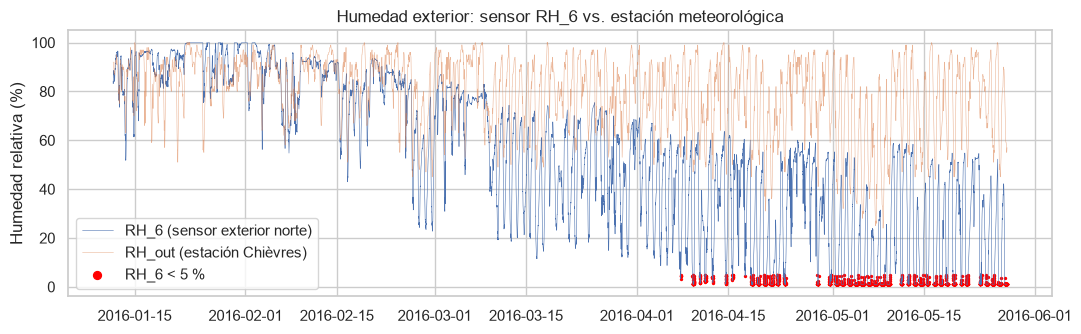

In [7]:
bajos = df['RH_6'] < 5
print('Registros con RH_6 < 5 %:', bajos.sum(), f'({bajos.mean():.1%} del total)')
b_tr = bajos.iloc[:corte]
print('\nRH_out (estación meteorológica) en esos mismos instantes:')
print(df.loc[bajos, 'RH_out'].describe().round(1))
print('\nProporción de lecturas < 5 % por mes, solo en entrenamiento:')
print(b_tr.groupby(tr['date'].dt.to_period('M')).mean().map('{:.1%}'.format))
ultimas = tr['date'] >= tr['date'].max() - pd.Timedelta(days=7)
print(f'Última semana de entrenamiento: {b_tr[ultimas].mean():.1%} de lecturas < 5 %')

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(df['date'], df['RH_6'], lw=0.4, label='RH_6 (sensor exterior norte)')
ax.plot(df['date'], df['RH_out'], lw=0.4, alpha=0.6, label='RH_out (estación Chièvres)')
ax.scatter(df.loc[bajos, 'date'], df.loc[bajos, 'RH_6'], s=2, c='red', label='RH_6 < 5 %')
ax.set_title('Humedad exterior: sensor RH_6 vs. estación meteorológica')
ax.set_ylabel('Humedad relativa (%)'); ax.legend(loc='lower left', markerscale=4)
plt.tight_layout(); plt.show()

Mientras `RH_6` marca menos de 5 %, la estación meteorológica (`RH_out`) registra humedades mucho más altas. Una
humedad exterior cercana a 1 % no es físicamente creíble en ese clima, así que se interpreta como **falla o saturación
del sensor**, no como un dato real.

Además, dentro del entrenamiento las fallas no aparecen al azar: empiezan en abril y se vuelven más frecuentes al
final del periodo, es decir, el sensor se está **degradando** y lo esperable es que siga fallando en el futuro.

**Alternativas consideradas:**
- *Eliminar esas filas:* descarta registros cuyo consumo y demás sensores son válidos y rompe la continuidad de la serie.
- *Imputar (p. ej. con la mediana de train):* la mediana de train corresponde sobre todo a invierno; si el sensor sigue
  fallando, el modelo recibiría en primavera un valor constante y artificial en una fracción creciente de registros.

**Decisión:** se **excluye la variable `RH_6`**. La humedad exterior ya está representada por `RH_out` (estación
meteorológica, sin fallas) y la temperatura exterior norte por `T6`, que funciona correctamente. Con esta decisión el
conjunto no tiene valores faltantes, por lo que **no se requiere imputación**.

## 5. Valores atípicos y asimetría del objetivo

En la semana 12 la regla IQR señaló 2 138 registros altos de `Appliances`. Se revisa cuándo ocurren.

Límite superior IQR (train): 175 Wh | registros por encima: 1776 (11.2%)
Asimetría de Appliances (train): 3.32
Asimetría de log1p(Appliances) (train): 1.15


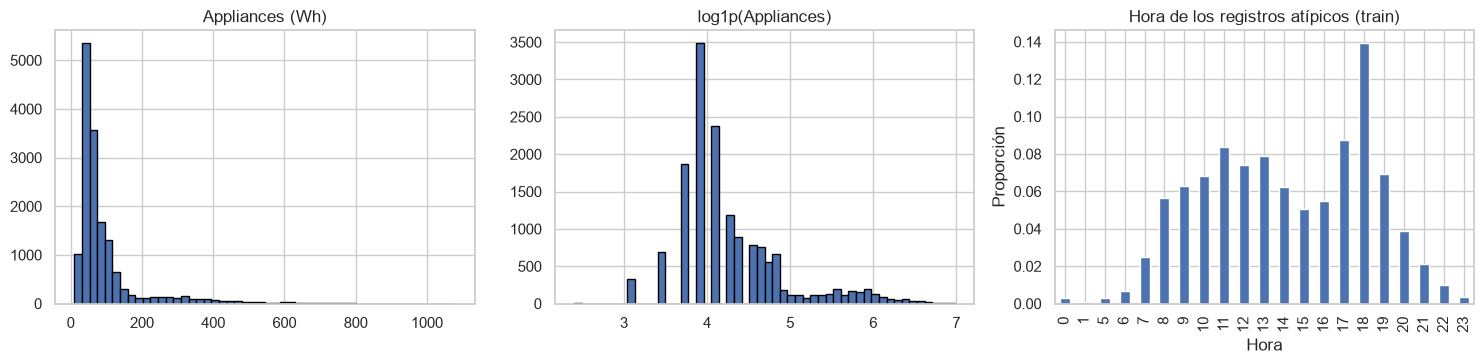

In [8]:
q1, q3 = tr['Appliances'].quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)
altos = tr['Appliances'] > lim_sup
print(f'Límite superior IQR (train): {lim_sup:.0f} Wh | registros por encima: {altos.sum()} ({altos.mean():.1%})')
print(f"Asimetría de Appliances (train): {tr['Appliances'].skew():.2f}")
print(f"Asimetría de log1p(Appliances) (train): {np.log1p(tr['Appliances']).skew():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(tr['Appliances'], bins=50, edgecolor='black'); axes[0].set_title('Appliances (Wh)')
axes[1].hist(np.log1p(tr['Appliances']), bins=50, edgecolor='black'); axes[1].set_title('log1p(Appliances)')
(tr.loc[altos, 'date'].dt.hour.value_counts(normalize=True).sort_index()
   .plot(kind='bar', ax=axes[2], title='Hora de los registros atípicos (train)'))
axes[2].set_xlabel('Hora'); axes[2].set_ylabel('Proporción')
plt.tight_layout(); plt.show()

Los consumos altos se concentran en horas de actividad del hogar (mañana y tarde-noche) y casi no aparecen de
madrugada: son **picos reales de uso** (horno, lavadora, etc.), no errores de medición.

**Decisión:**
- **No se eliminan ni recortan** los atípicos: son justamente los eventos de consumo que interesa estimar.
- Para reducir su influencia y la fuerte asimetría a la derecha, el modelo se entrenará sobre **`log1p(Appliances)`**
  (logaritmo de 1 + x) y las predicciones se devolverán a Wh con la transformación inversa `expm1`. Esta función no
  aprende parámetros de los datos, así que no genera fuga; se aplica dentro del modelo en el notebook 03
  (`TransformedTargetRegressor`).

## 6. Atributos temporales

El consumo depende fuertemente de la hora (en la semana 12: máximo a las 18:00, mínimo a las 03:00) y de la rutina
semanal. A partir de `date` se derivan:

- `hora_sin`, `hora_cos`: la hora del día (con minutos) codificada de forma **cíclica**, para que 23:50 y 00:00
  queden cerca entre sí (con la hora como número simple el modelo las vería a 23 unidades de distancia).
- `dia_semana`: 0 = lunes … 6 = domingo. Es **categórica** (no hay orden de magnitud entre días) y se codificará con
  *one-hot* en el preprocesador. Esa codificación ya incluye la información de fin de semana, por lo que no se agrega
  una variable `fin_semana` redundante.

Cada atributo se calcula con la marca de tiempo de su propia fila, sin usar registros futuros ni estadísticos del
conjunto, por lo que puede calcularse antes de la división sin riesgo de fuga.

In [9]:
hora = df['date'].dt.hour + df['date'].dt.minute / 60
df['hora_sin'] = np.sin(2 * np.pi * hora / 24)
df['hora_cos'] = np.cos(2 * np.pi * hora / 24)
df['dia_semana'] = df['date'].dt.day_of_week

df = df.drop(columns=['rv1', 'rv2', 'lights', 'RH_6'])
assert df.isna().sum().sum() == 0
print('Columnas finales:', df.shape[1])
df[['date', 'hora_sin', 'hora_cos', 'dia_semana']].head()

Columnas finales: 28


,date,hora_sin,hora_cos,dia_semana
0,2016-01-11 17:00:00,-0.966,-0.259,0
1,2016-01-11 17:10:00,-0.976,-0.216,0
2,2016-01-11 17:20:00,-0.985,-0.174,0
3,2016-01-11 17:30:00,-0.991,-0.131,0
4,2016-01-11 17:40:00,-0.996,-0.087,0


## 7. División cronológica entrenamiento / prueba

Se usa una división **cronológica 80/20**: el primer 80 % del periodo para entrenar y el 20 % final para probar.
No se usa una división aleatoria porque registros separados por 10 minutos son casi iguales; mezclarlos pondría en
el entrenamiento datos "vecinos" de los de prueba y daría una evaluación demasiado optimista. Así se simula el uso
real: aprender con el pasado y predecir el futuro. Para elegir parámetros, en el notebook 03 se usará
`TimeSeriesSplit` **dentro** del entrenamiento.

Entrenamiento: 2016-01-11 17:00:00 → 2016-04-30 08:10:00 (15788 registros)
Prueba:        2016-04-30 08:20:00 → 2016-05-27 18:00:00 (3947 registros)


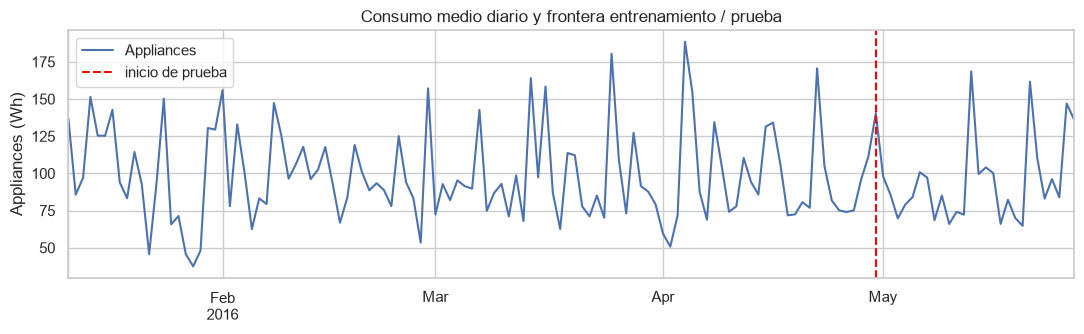

In [10]:
train = df.iloc[:corte].copy()
test = df.iloc[corte:].copy()
assert train['date'].max() < test['date'].min()
print('Entrenamiento:', train['date'].min(), '→', train['date'].max(), f'({len(train)} registros)')
print('Prueba:       ', test['date'].min(), '→', test['date'].max(), f'({len(test)} registros)')

diario = df.set_index('date')['Appliances'].resample('D').mean()
ax = diario.plot(figsize=(11, 3.5), title='Consumo medio diario y frontera entrenamiento / prueba')
ax.axvline(test['date'].min(), color='red', ls='--', label='inicio de prueba')
ax.set_ylabel('Appliances (Wh)'); ax.set_xlabel(''); ax.legend()
plt.tight_layout(); plt.show()

## 8. Preprocesador: codificación y escalado

Se define un `ColumnTransformer` de scikit-learn:

| Grupo | Columnas | Transformación | Motivo |
|---|---|---|---|
| Numéricas | T1–T9, RH_1–RH_9 (sin RH_6), clima exterior, `hora_sin`, `hora_cos` | `StandardScaler` | las variables tienen escalas muy distintas (°C, %, mm Hg, km/h); la regresión regularizada lo requiere para penalizar por igual |
| Categórica | `dia_semana` | `OneHotEncoder` | los días no tienen orden numérico |

**Clave contra la fuga de información:** el preprocesador se guarda **sin ajustar**. En el notebook 03 va dentro de un
`Pipeline` junto al modelo, de modo que las medias/desviaciones del escalado y las categorías del one-hot se aprenden
solo con los datos de entrenamiento de cada partición de validación y, al final, solo con el train completo.

In [11]:
NUM = TEMPS[:9] + [h for h in HUMS[:9] if h != 'RH_6'] + ['T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint',
                             'hora_sin', 'hora_cos']
CAT = ['dia_semana']

preprocesador = ColumnTransformer([
    ('num', StandardScaler(), NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT),
])
joblib.dump(preprocesador, 'preprocesador.joblib')   # se guarda SIN ajustar
print(len(NUM), 'numéricas +', len(CAT), 'categórica')

25 numéricas + 1 categórica


### 8.1 Comprobación: el preprocesador aprende solo del entrenamiento

Se ajusta una copia **solo con train** y se comparan los parámetros aprendidos con los estadísticos de train y de test.
Si no hay fuga, deben coincidir con train (no con test).

In [12]:
demo = clone(preprocesador).fit(train[NUM + CAT])

comp = pd.DataFrame({
    'media_scaler': demo.named_transformers_['num'].mean_,
    'media_train': train[NUM].mean().values,
    'media_test': test[NUM].mean().values,
}, index=NUM)
display(comp.head(10))
assert np.allclose(comp['media_scaler'], comp['media_train'])

Xt = demo.transform(train[NUM + CAT])
print('Matriz transformada de entrenamiento:', Xt.shape)
print('Columnas generadas por one-hot:', list(demo.get_feature_names_out()[-7:]))

,media_scaler,media_train,media_test
T1,21.152,21.152,23.824
T2,19.632,19.632,23.180
T3,21.589,21.589,24.983
T4,20.149,20.149,23.682
T5,18.958,18.958,22.130
T6,6.143,6.143,14.981
T7,19.553,19.553,23.122
T8,21.470,21.470,24.264
T9,18.769,18.769,22.355
RH_1,40.037,40.037,41.149


Matriz transformada de entrenamiento: (15788, 32)
Columnas generadas por one-hot: ['cat__dia_semana_0', 'cat__dia_semana_1', 'cat__dia_semana_2', 'cat__dia_semana_3', 'cat__dia_semana_4', 'cat__dia_semana_5', 'cat__dia_semana_6']


Las medias del escalador coinciden exactamente con las de entrenamiento y difieren de las de prueba: las
transformaciones se aprenden solo con el pasado, como exige la guía. La diferencia también muestra algo relevante
para el modelado: el periodo de prueba (mayo) es claramente **más cálido** que el de entrenamiento (enero–abril).

## 9. Exportación y resumen

Se exportan los conjuntos **limpios pero sin escalar** (el escalado y la codificación viven en el pipeline del
notebook 03). `date` se conserva solo para graficar.

In [13]:
COLS = ['date'] + NUM + CAT + ['Appliances']
train[COLS].to_csv(DATA / 'train_preparado.csv', index=False)
test[COLS].to_csv(DATA / 'test_preparado.csv', index=False)
print('train_preparado.csv:', train[COLS].shape, '| test_preparado.csv:', test[COLS].shape)

resumen = pd.DataFrame([
    ('date', 'Reemplazada por hora_sin, hora_cos y dia_semana', 'No extrapolable; la información útil es la hora y el día'),
    ('rv1, rv2', 'Excluidas', 'Variables aleatorias de los autores; idénticas y sin relación con el objetivo'),
    ('lights', 'Excluida', 'Consumo simultáneo al objetivo (fuga) y casi constante'),
    ('RH_6', 'Excluida (no se imputa)', 'Sensor con lecturas < 5 % implausibles y creciente frecuencia de falla; cubierta por RH_out y T6'),
    ('Nulos / duplicados', 'No hay; no se requiere imputación ni eliminación', 'Verificado con asserts'),
    ('Atípicos de Appliances', 'Se conservan', 'Picos reales de uso en horas de actividad'),
    ('Appliances', 'log1p al entrenar, expm1 al predecir', 'Asimetría fuerte a la derecha'),
    ('dia_semana', 'One-hot', 'Categórica sin orden'),
    ('Numéricas', 'StandardScaler (ajustado con train)', 'Escalas distintas; requerido por la regresión regularizada'),
    ('División', 'Cronológica 80/20', 'Serie temporal: entrenar con el pasado y probar con el futuro'),
], columns=['Variable / paso', 'Decisión', 'Justificación'])
resumen

train_preparado.csv: (15788, 28) | test_preparado.csv: (3947, 28)


,Variable / paso,Decisión,Justificación
0,date,"Reemplazada por hora_sin, hora_cos y dia_semana",No extrapolable; la información útil es la hor...
1,"rv1, rv2",Excluidas,Variables aleatorias de los autores; idénticas...
2,lights,Excluida,Consumo simultáneo al objetivo (fuga) y casi c...
3,RH_6,Excluida (no se imputa),Sensor con lecturas < 5 % implausibles y creci...
4,Nulos / duplicados,No hay; no se requiere imputación ni eliminación,Verificado con asserts
5,Atípicos de Appliances,Se conservan,Picos reales de uso en horas de actividad
6,Appliances,"log1p al entrenar, expm1 al predecir",Asimetría fuerte a la derecha
7,dia_semana,One-hot,Categórica sin orden
8,Numéricas,StandardScaler (ajustado con train),Escalas distintas; requerido por la regresión ...
9,División,Cronológica 80/20,Serie temporal: entrenar con el pasado y proba...


## 10. Conclusión de la preparación

El conjunto preparado conserva todos los registros: **15 788 de entrenamiento** (11-ene a 30-abr-2016) y **3 947 de
prueba** (30-abr a 27-may-2016), sin valores nulos ni duplicados, por lo que no fue necesario imputar ni eliminar
filas. Quedan **26 predictores** (25 numéricos y `dia_semana`), que el preprocesador convierte en 32 columnas tras el
one-hot. Se excluyeron `rv1` y `rv2` (aleatorias e idénticas), `lights` (consumo simultáneo al objetivo → fuga),
`RH_6` (sensor con lecturas implausibles desde abril) y la fecha cruda (reemplazada por hora cíclica y día de la semana).
Los picos de consumo se conservaron y la asimetría del objetivo (3,32) se reducirá con `log1p` (1,15).

El escalado se ajustó solo con entrenamiento, y la comparación de medias dejó ver un hecho que condiciona el modelado:
el periodo de prueba es más cálido que el de entrenamiento (por ejemplo, `T6` promedia 15,0 °C en prueba frente a
6,1 °C en entrenamiento). El modelo tendrá que predecir condiciones que vio poco o nunca.